#### 4.1. Verifying libraries

In [ ]:
from importlib.metadata import version

used_libraries = [
    "matplotlib",
    "torch",
    "tokenizers"
]

for lib in used_libraries:
    try:
        v = version(lib)
        print(f'{lib}: {v}')
    except Exception as e:
        print(f'{lib}: Not found')

matplotlib: 3.11.2
reasoning_from_scratch: Not found
torch: 2.4.1+cu124
tokenizers: 0.23.3


#### 4.2. Loading a pre-trained model

In [4]:
import torch
from reasoning_utils import get_device
from reasoning_utils import load_model_and_tokenizer

device = get_device()

model, tokenizer = load_model_and_tokenizer(
    which_model="base",
    device=device,
    use_compile=False
)

Using NVIDIA CUDA GPU
✓ qwen3\qwen3-0.6B-base.pth already up-to-date


d:\Stuffs\FunProjects\DumLRM\src\dumlrm\chapters\reasoning_from_scratch\ch03.py:82: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path

In [5]:
from reasoning_utils import render_prompt

raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)
prompt = render_prompt(raw_prompt)

print(prompt)

You are a helpful math assistant.
Answer the question and write the final result on a new line as:
\boxed{ANSWER}

Question:
Half the value of $3x-9$ is $x+37$. What is the value of $x$?

Answer:


#### 4.3. Building a flexible text generation function

In [6]:
from reasoning_utils import generate_text_basic_stream_cache

def generate_text_stream_concat_flex(
    model, tokenizer, prompt, device, max_new_tokens, verbose=False, generate_func=None, **generate_kwargs
):
    input_ids = torch.tensor(
        tokenizer.encode(prompt), device=device
    ).unsqueeze(0)

    if generate_func is None:
        generate_func = generate_text_basic_stream_cache

    generated_ids = []

    for token in generate_func(
        model=model,
        token_ids=input_ids,
        max_new_tokens=max_new_tokens,
        eos_token_id=tokenizer.eos_token_id,
        **generate_kwargs
    ):
        token_id = token.squeeze().item()
        generated_ids.append(token_id)

        if verbose:
            decoded_text = tokenizer.decode([token_id])
            print(decoded_text, end="", flush=True)
    
    return tokenizer.decode(generated_ids)

In [7]:
response = generate_text_stream_concat_flex(
    model=model,
    tokenizer=tokenizer,
    prompt=prompt,
    device=device,
    max_new_tokens=256,
    verbose=True,
)

 \boxed{20}

#### 4.4. Generating better responses with chain-of-thought prompting

In [8]:
prompt = prompt + "\n\nExplain step by step."
response = generate_text_stream_concat_flex(
    model=model,
    tokenizer=tokenizer,
    prompt=prompt,
    device=device,
    max_new_tokens=2048,
    verbose=True,
)

 To solve the problem, we need to find the value of \( x \) such that half the value of \( 3x - 9 \) is equal to \( x + 37 \).

### Step 1: Set up the equation
We are given that half the value of \( 3x - 9 \) is equal to \( x + 37 \). This can be written as:
\[
\frac{1}{2}(3x - 9) = x + 37
\]

### Step 2: Eliminate the fraction
To eliminate the fraction, multiply both sides of the equation by 2:
\[
2 \cdot \frac{1}{2}(3x - 9) = 2(x + 37)
\]
Simplifying both sides:
\[
3x - 9 = 2x + 74
\]

### Step 3: Solve for \( x \)
Subtract \( 2x \) from both sides to isolate \( x \):
\[
3x - 2x - 9 = 74
\]
Simplify:
\[
x - 9 = 74
\]
Add 9 to both sides to solve for \( x \):
\[
x = 74 + 9
\]
\[
x = 83
\]

### Final Answer:
\[
\boxed{83}
\]

#### 4.5. Controlling output diversity with temperature scaling

##### 4.5.1. Understanding the process of selecting the next token

In [9]:
ex_prompt = "capital of Germany is"

response = generate_text_stream_concat_flex(
    model=model,
    tokenizer=tokenizer,
    prompt=ex_prompt,
    device=device,
    max_new_tokens=1,
    verbose=False,
 )

input_token_ids = torch.tensor(
    tokenizer.encode(ex_prompt), device=device
).unsqueeze(0)

with torch.inference_mode():
    next_token_ids = model(input_token_ids)[:, -1]

max_token_ids = torch.argmax(next_token_ids)
print(f"Next token id: {max_token_ids}")
print(f"Next token: {tokenizer.decode([max_token_ids])}")

Next token id: 44581
Next token:  berlin


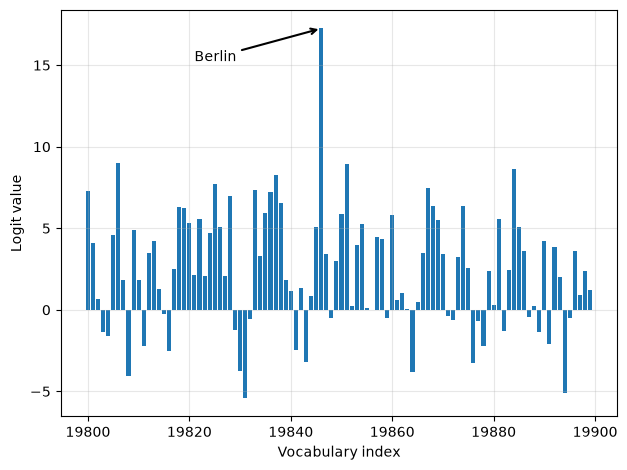

In [10]:
import matplotlib.pyplot as plt

def plot_scores_bar(
    next_token_logits, start=19_800, end=19_900,
    arrow=True, ylabel="Logit value"
):
    # Select vocabulary subsection
    x = torch.arange(start, end)

    # .cpu() is a shortcut for to(torch.device("cpu"))
    logits_section = next_token_logits[0, start:end].float().cpu()

    # Plot logits
    plt.bar(x, logits_section)
    plt.xlabel("Vocabulary index")
    plt.ylabel(ylabel)

    # Highlight max logit
    if arrow:
        max_idx = torch.argmax(logits_section)
        plt.annotate(
            "Berlin",
            xy=(x[max_idx], logits_section[max_idx]),
            xytext=(x[max_idx] - 25, logits_section[max_idx] - 2),
            arrowprops={
                "facecolor": "black", "arrowstyle": "->", "lw": 1.5
            },
            fontsize=10,
        )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_scores_bar(next_token_logits=next_token_ids)

##### 4.5.2. Rescaling token scores (logits) via a temperature parameter

In [11]:
def scale_logits_by_temperature(logits, temperature):
    if temperature <= 0:
        raise ValueError("temperature must be positive")
    return logits / temperature

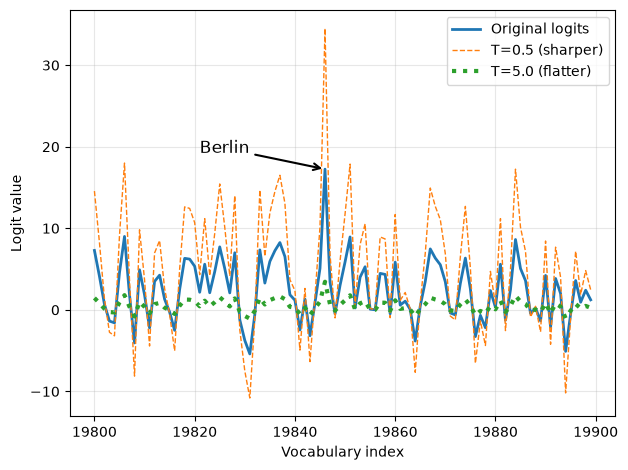

In [12]:
def plot_logits_with_temperature(
    next_token_logits, start=19_800, end=19_900,
    temps=(0.5, 5.0),
):
    x = torch.arange(start, end)
    logits_orig = next_token_logits[0, start:end].float().cpu()

    # Apply temperature scaling
    logits_scaled = [
        scale_logits_by_temperature(logits_orig, T) for T in temps
    ]
    # Plot logits
    plt.plot(x, logits_orig, label="Original logits", lw=2)
    plt.plot(
        x, logits_scaled[0],
        label=f"T={temps[0]} (sharper)", ls="--", lw=1
    )
    plt.plot(
        x, logits_scaled[1],
        label=f"T={temps[1]} (flatter)", ls=":", lw=3
    )

    # Highlight max logit
    max_idx = torch.argmax(logits_orig)
    plt.annotate(
        "Berlin",
        xy=(x[max_idx], logits_orig[max_idx]),
        xytext=(x[max_idx] - 25, logits_orig[max_idx] + 2),
        arrowprops={"facecolor": "black", "arrowstyle": "->", "lw": 1.5},
        fontsize=12,
    )

    plt.xlabel("Vocabulary index")
    plt.ylabel("Logit value")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_logits_with_temperature(
    next_token_ids,
    temps=(0.5, 5.0)
)

##### 4.5.3. Sampling the next token from a probability distribution

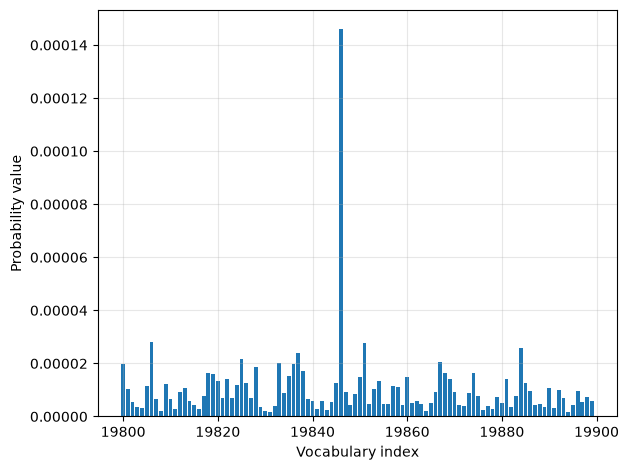

In [13]:
rescaled_logits = scale_logits_by_temperature(next_token_ids, temperature=5)
next_token_probas = torch.softmax(rescaled_logits, dim=-1)

plot_scores_bar(
    next_token_probas, arrow=False, ylabel="Probability value"
)

##### 4.5.4. Sample token according to probabilities using Multinomial

In [14]:
sample_token = torch.multinomial(next_token_probas, num_samples=1).item()
print(
    "Sampled token: ", sample_token
    , " -> ", tokenizer.decode([sample_token])
)

Sampled token:  113939  ->  最好是


In [15]:
def count_samples(probas, num_samples=1000, threshold=1, tokenizer=None):
    # draw samples according to probabilities
    samples = torch.multinomial(probas, num_samples=num_samples, replacement=True)
    
    # count how many times each token was sampled
    counts = torch.bincount(samples.squeeze(0), minlength=1)

    # print results
    for i, c in enumerate(counts):
        if c > threshold:
            if tokenizer is None:
                print(f"Vocab index {i} : {c.item()}x")
            else:
                print(f"`{tokenizer.decode([i])}` : {c.item()}x")

In [16]:
probas_lowT = torch.softmax(scale_logits_by_temperature(next_token_ids, temperature=0.35), dim=-1)
count_samples(probas_lowT, num_samples=1000, threshold=50, tokenizer=tokenizer)

`
` : 255x
` Berlin` : 101x
` berlin` : 481x


##### 4.5.5. Adding temperature scaling to the next generation funtion

In [17]:
from reasoning_utils import KVCache

@torch.inference_mode()
def generate_text_temp_stream_cache(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id=None,
    temperature=1.0,
):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()

    out = model(token_ids, cache=cache)[:, -1]

    for step in range(max_new_tokens):
        if temperature is None or temperature == 0.:
            next_token = torch.argmax(out, dim=-1, keepdim=True)

        else:
            # apply temperature scaling
            logits = scale_logits_by_temperature(out, temperature)

            # convert to probabilities
            probas = torch.softmax(logits, dim=-1)

            # sample token according to probabilities
            next_token = torch.multinomial(probas, num_samples=1)
            
        if (eos_token_id is not None
                and torch.all(next_token == eos_token_id)):
            break

        yield next_token
        if step + 1 < max_new_tokens:  # Skips the forward pass after the last token is generated
            out = model(next_token, cache=cache)[:, -1]

In [18]:
response = generate_text_stream_concat_flex(
    model=model,
    tokenizer=tokenizer,
    prompt=prompt,
    device=device,
    max_new_tokens=2048,
    verbose=True,
    generate_func=generate_text_temp_stream_cache,
    temperature=0.5
)

 To solve the problem, follow these steps:

1. **Understand the problem**: We are given that half the value of \(3x - 9\) is equal to \(x + 37\). We need to find the value of \(x\).

2. **Set up the equation**: According to the problem, half of \(3x - 9\) is equal to \(x + 37\). Mathematically, this can be written as:
   \[
   \frac{1}{2} \times (3x - 9) = x + 37
   \]

3. **Simplify the equation**: First, multiply both sides of the equation by 2 to eliminate the fraction:
   \[
   3x - 9 = 2(x + 37)
   \]

4. **Distribute the 2**: Distribute the 2 on the right side of the equation:
   \[
   3x - 9 = 2x + 74
   \]

5. **Isolate the variable \(x\)**: Subtract \(2x\) from both sides to get all the \(x\) terms on one side:
   \[
   3x - 2x - 9 = 74
   \]
   Simplifying this, we get:
   \[
   x - 9 = 74
   \]

6. **Solve for \(x\)**: Add 9 to both sides to isolate \(x\):
   \[
   x = 74 + 9
   \]
   Simplifying this, we get:
   \[
   x = 83
   \]

Therefore, the value of \(x\) is \(\boxed{

#### 4.6. Balancing diversity and coherence with top-p sampling

##### 4.6.1 Selecting a subset of top-p tokens

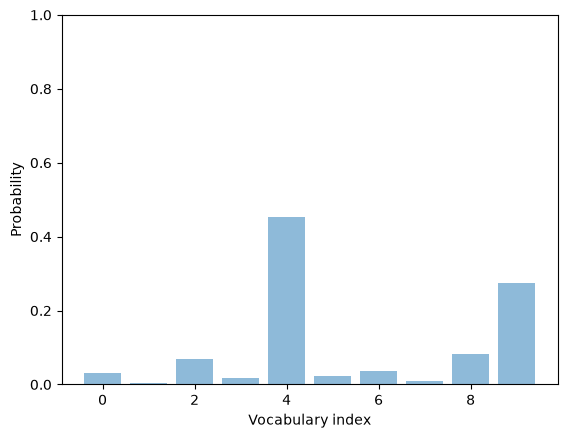

In [19]:
# get logits
toy_logits = torch.tensor(
    [-0.7, -3.0, 0.1, -1.2, 2.0, -1.0, -0.5, -2.0, 0.3, 1.5]
)

# apply temperature scaling
toy_logits_scaled = scale_logits_by_temperature(toy_logits, temperature=1.)

# convert to probabilities
toy_probas = torch.softmax(toy_logits_scaled, dim=-1)

plt.bar(
    torch.arange(len(toy_logits_scaled)), toy_probas,
    alpha=0.5
)

plt.ylim([0, 1])
plt.xlabel("Vocabulary index")
plt.ylabel("Probability")
# plt.savefig("12.pdf")
plt.show()

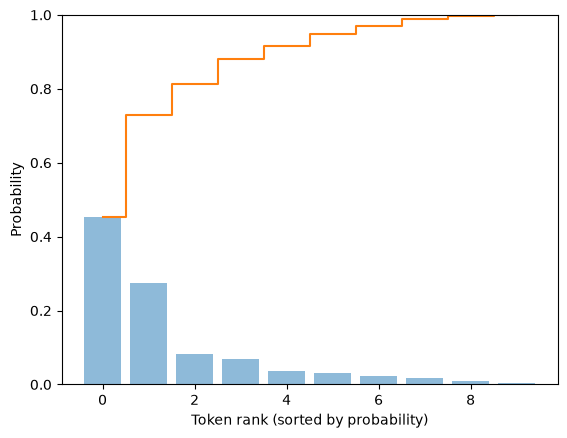

In [20]:
# Sort by descending probability
sorted_probas, sorted_idx = torch.sort(toy_probas, descending=True)

# Compute cumulative sum
cumsum = torch.cumsum(sorted_probas, dim=-1)

plt.bar(
    torch.arange(len(sorted_probas)), sorted_probas, 
        alpha=0.5
)
plt.step(
    torch.arange(len(cumsum)), cumsum, 
    where="mid", color="C1", label="Cumulative sum"
)

plt.ylim([0, 1])
plt.xlabel("Token rank (sorted by probability)")
plt.ylabel("Probability")
plt.show()

In [21]:
# Apply top-p threshold (e.g., keep tokens until cumulative mass > 0.8)
top_p = 0.8
keep_mask = cumsum <= top_p
n_kept = torch.sum(keep_mask).item()
print("Cumulative sum:", cumsum)
print("Tokens kept:", n_kept)

Cumulative sum: tensor([0.4538, 0.7290, 0.8119, 0.8798, 0.9170, 0.9475, 0.9701, 0.9886, 0.9969,
        1.0000])
Tokens kept: 2


Tokens kept: 3


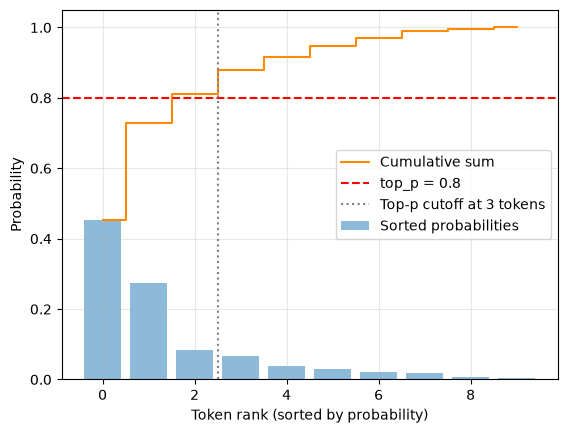

In [22]:
# A more common variant is to include the token that crosses the threshold
keep_mask = (cumsum - sorted_probas) < top_p
n_kept = keep_mask.sum().item()
print("Tokens kept:", n_kept)

plt.bar(
    torch.arange(len(sorted_probas)), sorted_probas, 
    alpha=0.5, label="Sorted probabilities"
)
plt.step(
    torch.arange(len(cumsum)), cumsum, where="mid",
    color="darkorange", label="Cumulative sum"
)

# Highlight cutoff
plt.axhline(
    top_p, color="red", linestyle="--",
    label=f"top_p = {top_p}"
)
plt.axvline(
    n_kept - 0.5, color="gray", linestyle=":",
    label=f"Top-p cutoff at {n_kept} tokens"
)

plt.xlabel("Token rank (sorted by probability)")
plt.ylabel("Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0, 1.05)
# plt.savefig("14.pdf")
plt.show()

In [23]:
# Zero out beyond cutoff
kept_sorted = torch.where(
    keep_mask, sorted_probas,
    torch.zeros_like(sorted_probas)
)

# Map back to original order
filtered = torch.zeros_like(toy_probas).scatter(0, sorted_idx, kept_sorted)

print(filtered)

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.4538, 0.0000, 0.0000, 0.0000, 0.0829,
        0.2752])


In [24]:
# Renormalize to sum to 1
denom = torch.sum(filtered).clamp_min(1e-12)
renormalized = filtered / denom
print(renormalized)

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.5589, 0.0000, 0.0000, 0.0000, 0.1021,
        0.3390])


##### 4.6.2 Adding a top-p filter to the text generation function

In [25]:
def top_p_filter(probas, top_p):
    if top_p is None or top_p >= 1.0:
        return probas

    # Step 1: Sort by descending probability
    sorted_probas, sorted_idx = torch.sort(probas, dim=1, descending=True)

    # Step 2: Cumulative sum
    cumprobas = torch.cumsum(sorted_probas, dim=1)

    # Step 3.1: Keep tokens where prefix cumulative mass (before token) is < top_p
    # Example: [0.5, 0.41, 0.09] with top_p=0.9 should keep the first two tokens
    prefix = cumprobas - sorted_probas   # cumulative mass before each token
    keep = prefix < top_p
    # Always keep at least one token (fallback for very small/non-positive top_p)
    keep[:, 0] = True    

    # Step 3.2: Zero out beyond cutoff
    kept_sorted = torch.where(
        keep, sorted_probas,
        torch.zeros_like(sorted_probas)
    )
    # Step 3.3: Map back to original order
    filtered = torch.zeros_like(probas).scatter(1, sorted_idx, kept_sorted)

    # Step 4: Renormalize to sum to 1
    denom = torch.sum(filtered, dim=1, keepdim=True).clamp_min(1e-12)
    return filtered / denom

In [26]:
from reasoning_utils import KVCache

@torch.inference_mode()
def generate_text_top_p_stream_cache(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id=None,
    temperature=1.0,
    top_p=None
):
    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()

    out = model(token_ids, cache=cache)[:, -1]

    for step in range(max_new_tokens):
        if temperature is None or temperature == 0.:
            next_token = torch.argmax(out, dim=-1, keepdim=True)

        else:
            logits = scale_logits_by_temperature(out, temperature)
            probas = torch.softmax(logits, dim=-1)

            # apply top_p
            probas = top_p_filter(probas, top_p)

            next_token = torch.multinomial(probas, num_samples=1)
            
        if (eos_token_id is not None
                and torch.all(next_token == eos_token_id)):
            break

        yield next_token
        if step + 1 < max_new_tokens:
            out = model(next_token, cache=cache)[:, -1]

In [27]:
response = generate_text_stream_concat_flex(
    model=model,
    tokenizer=tokenizer,
    prompt=prompt,
    device=device,
    max_new_tokens=2048,
    verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=1.1,
    top_p=0.8
)

#### 4.7. Improving response accuracy with self-consistency

In [34]:
from reasoning_utils import extract_final_candidate
from collections import Counter
import time

def self_consistency_vote(
        model, tokenizer, prompt, device,
        num_samples=10, temperature=0.8, top_p=0.9, max_new_tokens=2048,
        show_progress=True, show_long_answer=False, seed=None
):
    full_answers, short_answers = [], []
    
    start_time = time.time()    

    # sample multiple answers
    for i in range(num_samples):
        if seed is not None:
            torch.manual_seed(seed + i + 1)

        answer = generate_text_stream_concat_flex(
            model=model, tokenizer=tokenizer, prompt=prompt, device=device,
            max_new_tokens=max_new_tokens, verbose=show_long_answer, 
            generate_func=generate_text_top_p_stream_cache, 
            temperature=temperature, top_p=top_p
        )

        # extract final (short) answer
        short = extract_final_candidate(
            answer, fallback="number_then_full"
        )
        full_answers.append(answer)
        short_answers.append(short)
        if show_progress:
            print(f"[Sample {i+1}/{num_samples}] -> {short!r}")

    counts = Counter(short_answers)
    groups = {s: [] for s in counts}
    for idx, s in enumerate(short_answers):
        groups[s].append(idx)

    mc = counts.most_common()
    if not mc:
        majority_winners, final_answer = [], None
    else:
        top_freq = mc[0][1]
        majority_winners = [s for s, f in mc if f == top_freq]
        final_answer = mc[0][0] if len(majority_winners) == 1 else None

    return {
        "full": full_answers,
        "short": short_answers,
        "counts": counts,
        "groups": groups,
        "majority_winners": majority_winners,
        "final_answer": final_answer,
        "elapsed": time.time() - start_time
    }

In [38]:
results = self_consistency_vote(
    model, tokenizer, prompt, device,
    num_samples=5, temperature=0.8, top_p=0.9, max_new_tokens=2048,
    show_progress=True, show_long_answer=False, seed=42
)

print(
    f"Final answer: {results['final_answer']!r}\n"
    f"Majority winners: {results['majority_winners']!r}\n"
    f"Vote counts: {dict(results['counts'])}\n"
    f"Time elapsed: {results['elapsed']:.2f}s"""
)

[Sample 1/5] -> '83'
[Sample 2/5] -> '11'
[Sample 3/5] -> ''
[Sample 4/5] -> ''
[Sample 5/5] -> '83'
Final answer: None
Majority winners: ['83', '']
Vote counts: {'83': 2, '11': 1, '': 2}
Time elapsed: 39.92s


#### 4.8. Batched self-consistency

In [31]:
@torch.inference_mode()
def generate_text_top_p_batched(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id=None,
    temperature=0.0,
    top_p=None,
    seed=None,
    seed_offset=0,
):
    """Batched variant of top-p sampling used for self-consistency."""

    model.eval()
    cache = KVCache(n_layers=model.cfg["n_layers"])
    model.reset_kv_cache()

    device = token_ids.device
    batch_size = token_ids.size(0)
    generated_tokens = [[] for _ in range(batch_size)]
    finished = torch.zeros(batch_size, dtype=torch.bool, device=device)

    rngs = None
    if seed is not None and temperature not in (None, 1.0):
        rngs = []
        for idx in range(batch_size):
            gen = torch.Generator(device="cpu")
            gen.manual_seed(seed + seed_offset + idx + 1)
            rngs.append(gen)

    out = model(token_ids, cache=cache)[:, -1]

    for step in range(max_new_tokens):
        if temperature is None or temperature == 0.0:
            next_token = torch.argmax(out, dim=-1, keepdim=True)
            if eos_token_id is not None and torch.any(finished):
                fill = torch.full_like(next_token, eos_token_id)
                next_token = torch.where(finished.view(-1, 1), fill, next_token)
        else:
            logits = scale_logits_by_temperature(out, temperature)
            probas = torch.softmax(logits, dim=-1)
            probas = top_p_filter(probas, top_p)
            probas_cpu = probas.cpu()
            sampled = []
            for idx in range(batch_size):
                if finished[idx]:
                    fill_value = eos_token_id if eos_token_id is not None else 0
                    sampled.append(torch.tensor([fill_value], dtype=torch.long))
                    continue
                generator = rngs[idx] if rngs is not None else None
                sampled.append(
                    torch.multinomial(
                        probas_cpu[idx],
                        num_samples=1,
                        generator=generator,
                    )
                )
            next_token = torch.stack(sampled, dim=0).to(device)

        eos_mask = torch.zeros(batch_size, dtype=torch.bool, device=device)
        if eos_token_id is not None:
            eos_mask = next_token.squeeze(1) == eos_token_id

        for idx in range(batch_size):
            if finished[idx]:
                continue
            token_val = next_token[idx, 0].item()
            if eos_token_id is not None and token_val == eos_token_id:
                finished[idx] = True
            else:
                generated_tokens[idx].append(token_val)

        if eos_token_id is not None:
            finished = finished | eos_mask

        if torch.all(finished):
            break

        if step + 1 < max_new_tokens:  # Skips the forward pass after the last token is generated
            out = model(next_token, cache=cache)[:, -1]

    return generated_tokens

In [36]:
def self_consistency_vote_batched(
    model,
    tokenizer,
    prompt,
    device,
    num_samples=10,
    temperature=0.8,
    top_p=0.9,
    max_new_tokens=2048,
    show_progress=True,
    show_long_answer=False,
    seed=None,
):
    full_answers, short_answers = [], []
    counts = Counter()
    groups = {}
    majority_winners, final_answer = [], None
    start_time = time.time()

    batch_size = max(1, num_samples)
    prompt_ids = torch.tensor(
        tokenizer.encode(prompt), device=device, dtype=torch.long
    ).unsqueeze(0)

    while len(full_answers) < num_samples:
        remaining = num_samples - len(full_answers)
        current_batch = min(batch_size, remaining)
        token_batch = prompt_ids.repeat(current_batch, 1)

        token_lists = generate_text_top_p_batched(
            model=model,
            token_ids=token_batch,
            max_new_tokens=max_new_tokens,
            eos_token_id=tokenizer.eos_token_id,
            temperature=temperature,
            top_p=top_p,
            seed=seed,
            seed_offset=len(full_answers),
        )
        answers = [tokenizer.decode(tokens) for tokens in token_lists]

        for answer in answers:
            sample_idx = len(full_answers)
            short = extract_final_candidate(answer, fallback="number_then_full")
            full_answers.append(answer)
            short_answers.append(short)
            counts[short] += 1
            groups.setdefault(short, []).append(sample_idx)

            if show_long_answer:
                print(answer)

            if show_progress:
                print(f"[Sample {sample_idx+1}/{num_samples}] → {short!r}")

    if final_answer is None:
        mc = counts.most_common()
        if mc:
            top_freq = mc[0][1]
            majority_winners = [s for s, f in mc if f == top_freq]
            final_answer = mc[0][0] if len(majority_winners) == 1 else None

    return {
        "full_answers": full_answers,
        "short_answers": short_answers,
        "counts": dict(counts),
        "groups": groups,
        "majority_winners": majority_winners,
        "final_answer": final_answer,
        "elapsed": time.time() - start_time
    }

In [37]:
results = self_consistency_vote_batched(
    model, tokenizer, prompt, device,
    num_samples=5, temperature=0.8, top_p=0.9, max_new_tokens=2048,
    show_progress=True, show_long_answer=False, seed=42
)

print(
    f"Final answer: {results['final_answer']!r}\n"
    f"Majority winners: {results['majority_winners']!r}\n"
    f"Vote counts: {dict(results['counts'])}\n"
    f"Time elapsed: {results['elapsed']:.2f}s"""
)

[Sample 1/5] → '83'
[Sample 2/5] → '83'
[Sample 3/5] → '83'
[Sample 4/5] → ''
[Sample 5/5] → '23'
Final answer: '83'
Majority winners: ['83']
Vote counts: {'83': 3, '': 1, '23': 1}
Time elapsed: 17.53s
